<a href="https://colab.research.google.com/github/eduardozurek/smart-sensors/blob/main/notebooks/01_ejemplo_guiado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IA para sensores — Ejemplo guiado
### IBERSENSOR 2026 · Universidad del Norte

**Archivo:** `01_ejemplo_guiado.ipynb`  
**Datos:** WISDM, sujeto 1603, acelerómetro del smartphone  
**Objetivo:** clasificar actividades humanas a partir de características procesadas de movimiento.

**Ruta del taller:** lectura ARFF → exploración → selección de variables → entrenamiento → evaluación → interpretación.

> **Alcance metodológico:** este notebook realiza una evaluación exploratoria *intra-sujeto*. El ARFF procesado no proporciona necesariamente identificadores temporales suficientes para garantizar una partición libre de dependencia entre ventanas. Una buena puntuación aquí **no** demuestra generalización a otras personas o sesiones.

## 1. Preparar el entorno

Necesitamos `pandas`, `numpy`, `scipy`, `matplotlib` y `scikit-learn`. Si falta alguna biblioteca, ejecuta en otra celda `%pip install pandas numpy scipy matplotlib scikit-learn` y reinicia el kernel si fuera necesario.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from io import StringIO
from urllib.request import urlopen
from scipy.io import arff
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    ConfusionMatrixDisplay
)

SEED = 42
SUJETO = 1603
SENSOR = "accel"
DISPOSITIVO = "phone"
ACTIVIDADES = ["A", "B", "C", "D", "E"]  # Cambiar a None para usar todas las actividades

print("Sujeto:", SUJETO)
print("Actividades seleccionadas:", ACTIVIDADES or "Todas")

Sujeto: 1603
Actividades seleccionadas: ['A', 'B', 'C', 'D', 'E']


## 2. Descargar y leer el ARFF desde GitHub

La dirección `github.com/.../tree/...` muestra una carpeta en el navegador. Para leer un archivo concreto usamos su dirección **raw**. `StringIO` convierte el texto descargado en un flujo compatible con `scipy.io.arff.loadarff`.

In [2]:
def leer_wisdm(sujeto, sensor="accel", dispositivo="phone"):
    base = "https://raw.githubusercontent.com/eduardozurek/ia/main/_005_clustering/WISDM/"
    nombre = f"data_{sujeto}_{sensor}_{dispositivo}.arff"
    url = base + nombre
    print("Leyendo:", url)
    with urlopen(url, timeout=30) as respuesta:
        contenido = respuesta.read().decode("utf-8-sig")
    datos, metadatos = arff.loadarff(StringIO(contenido))
    tabla = pd.DataFrame(datos)
    tabla.columns = tabla.columns.str.strip('"').str.strip()
    for col in tabla.select_dtypes(include=["object"]).columns:
        tabla[col] = tabla[col].map(
            lambda v: v.decode("utf-8") if isinstance(v, bytes) else v
        )
    return tabla, metadatos

try:
    df, metadatos = leer_wisdm(SUJETO, SENSOR, DISPOSITIVO)
except Exception as exc:
    raise RuntimeError(
        "No fue posible leer el ARFF. Verifica la conexión, la rama main, "
        "la ruta y el nombre del archivo en GitHub."
    ) from exc

print("Dimensiones:", df.shape)
display(df.head())

Leyendo: https://raw.githubusercontent.com/eduardozurek/ia/main/_005_clustering/WISDM/data_1603_accel_phone.arff
Dimensiones: (409, 93)


,ACTIVITY,X0,X1,X2,X3,X4,X5,X6,X7,X8,...,ZMFCC11,ZMFCC12,XYCOS,XZCOS,YZCOS,XYCOR,XZCOR,YZCOR,RESULTANT,class
0,A,0.205,0.130,0.300,0.175,0.065,0.080,0.03,0.010,0.005,...,0.638216,0.630015,0.355715,0.255810,0.098828,0.094608,0.252518,0.102834,11.4403,1603
1,A,0.210,0.135,0.325,0.230,0.055,0.020,0.02,0.005,0.000,...,0.606414,0.598621,0.393011,0.399566,0.128732,0.367878,0.396639,0.163752,11.2096,1603
2,A,0.195,0.185,0.225,0.250,0.090,0.015,0.02,0.015,0.005,...,0.611475,0.603617,0.435449,0.467736,0.130834,0.353874,0.462766,0.097135,11.5358,1603
3,A,0.210,0.155,0.255,0.225,0.095,0.020,0.03,0.010,0.000,...,0.655883,0.647455,0.414655,0.387189,0.129917,0.374226,0.387476,0.177059,11.5863,1603
4,A,0.205,0.185,0.205,0.265,0.070,0.020,0.02,0.015,0.015,...,0.654841,0.646426,0.414564,0.416695,0.160491,0.408718,0.406013,0.151663,11.8935,1603


## 3. Comprender las columnas

- **`ACTIVITY`**: actividad humana, **variable objetivo**.
- **`class`**: identificador de la persona, **no es la actividad**.
- **Otras 91 columnas**: características predictoras, como histogramas por eje (`X0`–`X9`), estadísticos (`XAVG`), coeficientes MFCC y relaciones entre ejes.

Cada fila representa un conjunto de características calculadas a partir de una ventana, no una lectura instantánea del acelerómetro.

In [3]:
print("Número total de columnas:", len(df.columns))
print("Columnas:")
print(df.columns.tolist())

if not {"ACTIVITY", "class"}.issubset(df.columns):
    raise ValueError("No se encontraron ACTIVITY y class. Revisa el esquema del ARFF.")

print("\nSujetos presentes:", df["class"].unique())
print("Actividades presentes:", sorted(df["ACTIVITY"].dropna().unique()))
print("Número de atributos predictivos:", len(df.columns) - 2)

if len(df.columns) != 93:
    print("Aviso: este archivo tiene un número de columnas distinto de las 93 esperadas.")

Número total de columnas: 93
Columnas:
['ACTIVITY', 'X0', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'Y0', 'Y1', 'Y2', 'Y3', 'Y4', 'Y5', 'Y6', 'Y7', 'Y8', 'Y9', 'Z0', 'Z1', 'Z2', 'Z3', 'Z4', 'Z5', 'Z6', 'Z7', 'Z8', 'Z9', 'XAVG', 'YAVG', 'ZAVG', 'XPEAK', 'YPEAK', 'ZPEAK', 'XABSOLDEV', 'YABSOLDEV', 'ZABSOLDEV', 'XSTANDDEV', 'YSTANDDEV', 'ZSTANDDEV', 'XVAR', 'YVAR', 'ZVAR', 'XMFCC0', 'XMFCC1', 'XMFCC2', 'XMFCC3', 'XMFCC4', 'XMFCC5', 'XMFCC6', 'XMFCC7', 'XMFCC8', 'XMFCC9', 'XMFCC10', 'XMFCC11', 'XMFCC12', 'YMFCC0', 'YMFCC1', 'YMFCC2', 'YMFCC3', 'YMFCC4', 'YMFCC5', 'YMFCC6', 'YMFCC7', 'YMFCC8', 'YMFCC9', 'YMFCC10', 'YMFCC11', 'YMFCC12', 'ZMFCC0', 'ZMFCC1', 'ZMFCC2', 'ZMFCC3', 'ZMFCC4', 'ZMFCC5', 'ZMFCC6', 'ZMFCC7', 'ZMFCC8', 'ZMFCC9', 'ZMFCC10', 'ZMFCC11', 'ZMFCC12', 'XYCOS', 'XZCOS', 'YZCOS', 'XYCOR', 'XZCOR', 'YZCOR', 'RESULTANT', 'class']

Sujetos presentes: ['1603']
Actividades presentes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'O', 'P', 'Q', 'R', 'S

## 4. Distribución de las actividades

Observa cuántas ventanas hay por actividad. Una distribución desigual puede hacer que el *accuracy* sea poco informativo por sí solo.

,Actividad,Ventanas
0,A,22
1,B,23
2,C,22
3,D,24
4,E,23
5,F,22
6,G,23
7,H,22
8,I,23
9,J,22


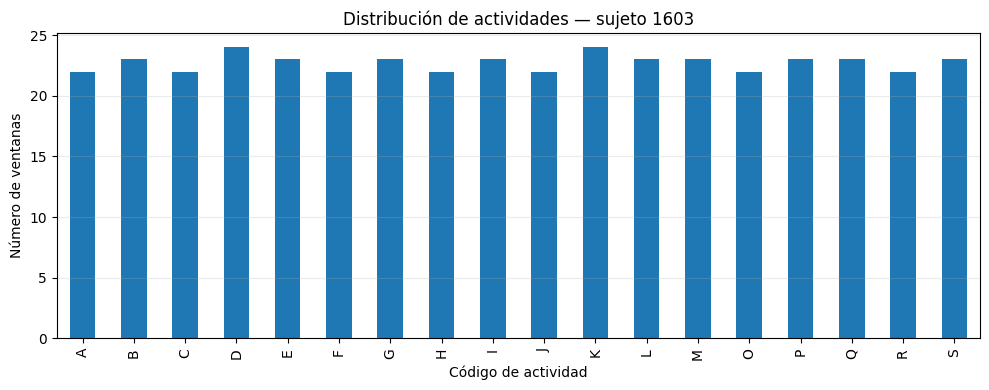

In [4]:
conteos = df["ACTIVITY"].value_counts().sort_index()
display(conteos.rename_axis("Actividad").reset_index(name="Ventanas"))

fig, ax = plt.subplots(figsize=(10, 4))
conteos.plot(kind="bar", ax=ax)
ax.set(title=f"Distribución de actividades — sujeto {SUJETO}",
       xlabel="Código de actividad", ylabel="Número de ventanas")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Preparar las variables `X` e `y`

Seleccionaremos inicialmente cinco actividades para facilitar la explicación. Eliminamos **ambas** columnas `ACTIVITY` y `class` de las entradas para evitar fuga directa de información de la etiqueta y excluir el identificador del sujeto.

Comprobaremos también valores faltantes y atributos no numéricos.

In [5]:
trabajo = df.copy()
if ACTIVIDADES is not None:
    trabajo = trabajo[trabajo["ACTIVITY"].isin(ACTIVIDADES)].copy()

X = trabajo.drop(columns=["ACTIVITY", "class"])
y = trabajo["ACTIVITY"].astype(str)

if X.empty or y.nunique() < 2:
    raise ValueError("Se necesitan ejemplos de al menos dos actividades.")

X = X.apply(pd.to_numeric, errors="raise")
X = X.replace([np.inf, -np.inf], np.nan)

print("Ejemplos:", len(X))
print("Características:", X.shape[1])
print("Actividades:", sorted(y.unique()))
print("Valores faltantes por columna (solo columnas afectadas):")
display(X.isna().sum().loc[lambda s: s > 0].to_frame("Faltantes"))

if X.isna().any().any():
    raise ValueError(
        "Hay valores faltantes/no finitos. Deben tratarse mediante una "
        "estrategia de imputación ajustada exclusivamente con entrenamiento."
    )

Ejemplos: 114
Características: 91
Actividades: ['A', 'B', 'C', 'D', 'E']
Valores faltantes por columna (solo columnas afectadas):


,Faltantes


## 6. Dividir los ejemplos en entrenamiento y prueba

Utilizamos un 80 % para entrenamiento y un 20 % para prueba, con estratificación por actividad.

⚠️ **Advertencia:** esta división aleatoria es únicamente didáctica y exploratoria. Si las ventanas proceden de segmentos contiguos o solapados, puede existir dependencia entre ambos conjuntos. El ARFF debe aportar metadatos temporales o de sesión para diseñar una validación temporal rigurosa.

In [6]:
conteos_seleccion = y.value_counts()
if conteos_seleccion.min() < 2:
    raise ValueError("Cada actividad necesita al menos dos ejemplos para estratificar.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Distribución entrenamiento:")
display(y_train.value_counts().sort_index().to_frame("Ventanas"))
print("Distribución prueba:")
display(y_test.value_counts().sort_index().to_frame("Ventanas"))

Entrenamiento: (91, 91)
Prueba: (23, 91)
Distribución entrenamiento:


,Ventanas
ACTIVITY,
A,18
B,18
C,18
D,19
E,18


Distribución prueba:


,Ventanas
ACTIVITY,
A,4
B,5
C,4
D,5
E,5


## 7. Entrenar Random Forest

Un *Random Forest* combina múltiples árboles de decisión. Fijamos la semilla y los hiperparámetros para facilitar la comparación entre grupos. Los árboles no requieren estandarización previa de las características.

In [7]:
modelo = RandomForestClassifier(
    n_estimators=100,
    random_state=SEED,
    n_jobs=-1
)
modelo.fit(X_train, y_train)
y_pred = modelo.predict(X_test)
print("Modelo entrenado; predicciones generadas:", len(y_pred))

Modelo entrenado; predicciones generadas: 23


## 8. Evaluar el desempeño

- **Accuracy:** proporción de ejemplos correctamente clasificados.
- **Precision:** de los ejemplos predichos como una actividad, cuántos eran correctos.
- **Recall:** de los ejemplos reales de una actividad, cuántos fueron detectados.
- **F1-macro:** media de los F1 por clase, sin ponderar por su frecuencia.

Conviene reportar tanto métricas globales como por actividad.

In [8]:
accuracy = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Accuracy: {accuracy:.4f}")
print(f"F1-macro: {f1_macro:.4f}")
print("\nReporte por actividad:")
print(classification_report(y_test, y_pred, zero_division=0))

reporte = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
clases = sorted(y.unique())
metricas_clase = pd.DataFrame(reporte).T.loc[clases, ["precision", "recall", "f1-score", "support"]]
display(metricas_clase)

Accuracy: 0.8696
F1-macro: 0.8688

Reporte por actividad:
              precision    recall  f1-score   support

           A       1.00      0.75      0.86         4
           B       0.83      1.00      0.91         5
           C       0.80      1.00      0.89         4
           D       0.80      0.80      0.80         5
           E       1.00      0.80      0.89         5

    accuracy                           0.87        23
   macro avg       0.89      0.87      0.87        23
weighted avg       0.89      0.87      0.87        23



,precision,recall,f1-score,support
A,1.000000,0.75,0.857143,4.0
B,0.833333,1.00,0.909091,5.0
C,0.800000,1.00,0.888889,4.0
D,0.800000,0.80,0.800000,5.0
E,1.000000,0.80,0.888889,5.0


## 9. Matriz de confusión

Las filas representan actividades **reales** y las columnas actividades **predichas**. La diagonal indica aciertos. Busca especialmente pares de actividades que el modelo confunda.

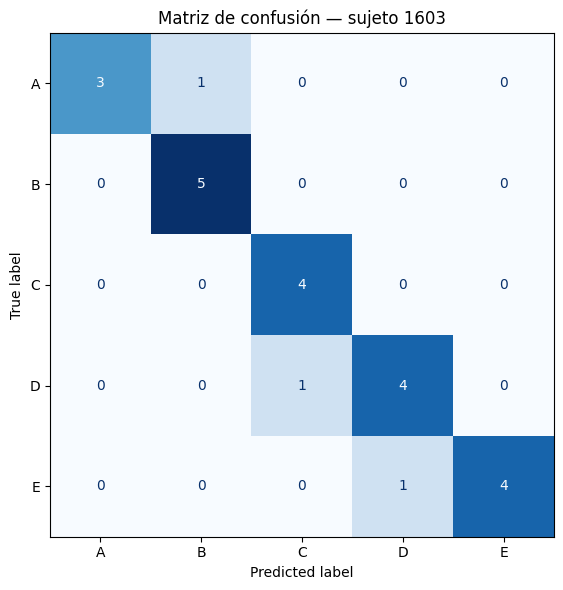

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=clases,
    display_labels=clases, cmap="Blues", ax=ax,
    values_format="d", colorbar=False
)
ax.set_title(f"Matriz de confusión — sujeto {SUJETO}")
plt.tight_layout()
plt.show()

## 10. Importancia de características

La importancia por reducción de impureza es útil como exploración, pero **no mide causalidad** y puede sesgarse ante atributos correlacionados o con diferentes propiedades estadísticas.

,Importancia
YAVG,0.043940
YMFCC9,0.032987
Y6,0.032793
Y3,0.027814
ZAVG,0.027531
Z0,0.026516
ZMFCC0,0.024414
YZCOS,0.023986
YSTANDDEV,0.022840
XYCOS,0.022154


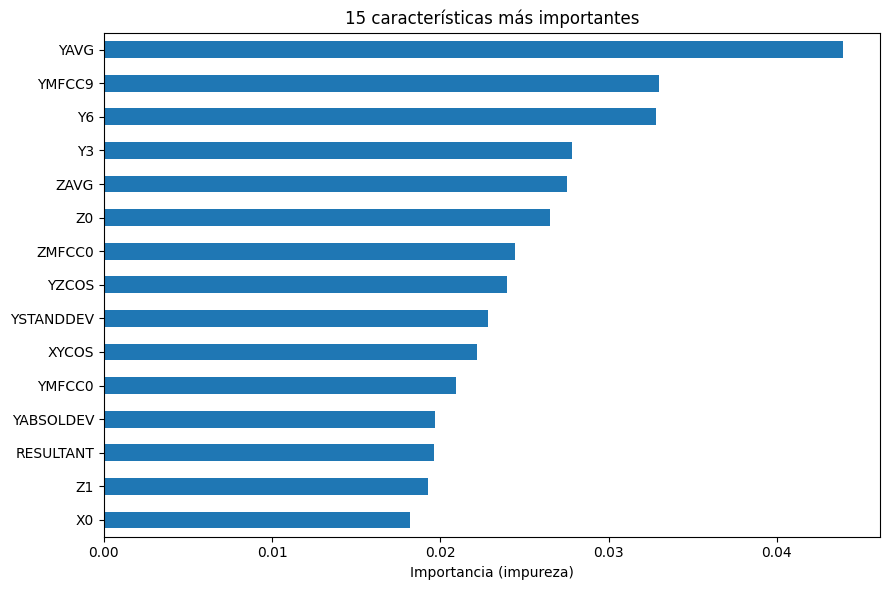

In [10]:
importancias = pd.Series(
    modelo.feature_importances_, index=X.columns, name="Importancia"
).sort_values(ascending=False)

display(importancias.head(15).to_frame())

fig, ax = plt.subplots(figsize=(9, 6))
importancias.head(15).sort_values().plot(kind="barh", ax=ax)
ax.set(title="15 características más importantes", xlabel="Importancia (impureza)", ylabel="")
plt.tight_layout()
plt.show()

## 11. Registrar resultados para comparar grupos

Cada equipo podrá ejecutar una copia del notebook cambiando únicamente `SUJETO`, manteniendo fijos actividades, partición, hiperparámetros y métricas. Las puntuaciones describen modelos **distintos entrenados para cada sujeto**; no constituyen una prueba inter-sujeto.

In [11]:
resumen = pd.DataFrame([{
    "sujeto": SUJETO,
    "sensor": SENSOR,
    "dispositivo": DISPOSITIVO,
    "actividades": ",".join(clases),
    "ejemplos": len(X),
    "caracteristicas": X.shape[1],
    "ejemplos_entrenamiento": len(X_train),
    "ejemplos_prueba": len(X_test),
    "accuracy": round(accuracy, 4),
    "f1_macro": round(f1_macro, 4),
    "caracteristica_principal": importancias.index[0],
    "protocolo": "aleatorio estratificado; exploratorio intra-sujeto"
}])
display(resumen)

# Opcional: guardar resultados locales
# resumen.to_csv(f"resultados_wisdm_{SUJETO}.csv", index=False)

,sujeto,sensor,dispositivo,actividades,ejemplos,caracteristicas,ejemplos_entrenamiento,ejemplos_prueba,accuracy,f1_macro,caracteristica_principal,protocolo
0,1603,accel,phone,"A,B,C,D,E",114,91,91,23,0.8696,0.8688,YAVG,aleatorio estratificado; exploratorio intra-su...


## 12. Preguntas para discutir

1. ¿Cuál es la actividad con mayor y menor F1-score?
2. ¿Qué pares de actividades se confunden más?
3. ¿Coinciden accuracy y F1-macro? ¿Por qué podrían diferir?
4. ¿Cuáles son las características más importantes? ¿Qué significan físicamente?
5. ¿Podemos afirmar que el modelo funcionará con un sujeto diferente? **No:** para eso se requiere evaluación inter-sujeto.
6. ¿Qué información adicional necesitaríamos para separar las ventanas por bloques temporales o sesiones?

### Referencias

- [WISDM en UCI](https://archive.ics.uci.edu/dataset/507/wisdm+smartphone+and+smartwatch+activity+and+biometrics+dataset)
- [Documentación de RandomForestClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
- [Métricas de clasificación](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)

**Nota:** para una evaluación más sólida, recuperar datos originales con marcas temporales, separar sesiones o bloques antes de extraer características y evitar ventanas solapadas entre entrenamiento y prueba.